# D03 — Superficie de volatilidad, volatilidad local y Heston

**Objetivos:** leer una superficie de renta variable (ATM, risk reversal, mariposa, skew 90-110); construir una
superficie sin arbitraje (SSVI); obtener la volatilidad local de Dupire y comprobar que reprecia las vanillas;
calibrar Heston y ver qué puede y qué no puede reproducir; entender cómo se mueve el smile cuando cae el índice y
qué significa para quien vende skew.

**Fuentes:** Hull cap. 20 (20.3 a 20.7) y 27 (27.2 y 27.3); Gatheral, *The Volatility Surface* (2006), cap. 1-3,
y Gatheral y Jacquier (2014) para SSVI; Schofield, *Equity Derivatives*, cap. 5 (5.8) y 6. Datos sintéticos.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent          # notebooks/ -> repository root
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from datetime import date
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)
plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.grid"] = True

from scipy.optimize import least_squares
from scipy.stats import norm
from derivlab.market import sample_market
from derivlab.curves import build_curves
from derivlab.equity import EquityMarket, SSVI, bs_price, implied_vol, local_vol_mc, heston_call, bs_greeks

estr, eur = build_curves(sample_market())
mkt = EquityMarket(estr)
surface = SSVI()
print(f"SSVI parameters: rho {surface.rho}, eta {surface.eta}, gamma {surface.gamma}; ATM vol 15.5% rising to 20% at long maturities")

SSVI parameters: rho -0.75, eta 1.0, gamma 0.45; ATM vol 15.5% rising to 20% at long maturities


## 1. Cómo se cotiza una superficie de renta variable

Se trabaja en *log-moneyness* $k = \ln(K/F_T)$. Las cotizaciones habituales:

- **ATM**: volatilidad en $k=0$ (ATM forward).
- **Risk reversal 25Δ**: $\sigma_{25\Delta C} - \sigma_{25\Delta P}$; en renta variable es negativo (los puts cuestan más).
- **Mariposa 25Δ**: $\tfrac12(\sigma_{25\Delta C} + \sigma_{25\Delta P}) - \sigma_{ATM}$, la curvatura.
- **Skew 90-110**: $\sigma(90\,\%) - \sigma(110\,\%)$ del spot, la forma habitual de hablar de skew en índices.

In [2]:
def k_at_delta(T, delta, call=True):
    """Log-moneyness whose forward delta (with the smile vol at that strike) equals +delta (call) or -delta (put)."""
    def f(k):
        v = surface.vol(k, T)
        d1 = (-k + 0.5 * v * v * T) / (v * np.sqrt(T))
        return (norm.cdf(d1) - delta) if call else (norm.cdf(d1) - 1 + delta)
    return brentq(f, -2.0, 2.0)

quotes = []
for T in [1 / 12, 0.25, 0.5, 1.0, 2.0]:
    kc, kp = k_at_delta(T, 0.25, True), k_at_delta(T, 0.25, False)
    F = mkt.forward(T)
    atm = surface.vol(0.0, T)
    quotes.append({"T": T, "ATM": atm, "RR 25d": surface.vol(kc, T) - surface.vol(kp, T),
                   "BF 25d": 0.5 * (surface.vol(kc, T) + surface.vol(kp, T)) - atm,
                   "skew 90-110": surface.vol(np.log(0.9 * mkt.spot / F), T) - surface.vol(np.log(1.1 * mkt.spot / F), T),
                   "25d put strike": F * np.exp(kp), "25d call strike": F * np.exp(kc)})
qt = pd.DataFrame(quotes)
print(qt.to_string(index=False, formatters={"T": "{:.3f}".format, "ATM": "{:.2%}".format, "RR 25d": "{:+.2%}".format,
      "BF 25d": "{:+.2%}".format, "skew 90-110": "{:.2%}".format, "25d put strike": "{:,.0f}".format,
      "25d call strike": "{:,.0f}".format}))
print(f"CASE 3m: ATM {qt.ATM[1]:.2%}, 25d RR {qt['RR 25d'][1]:+.2%}, 90-110 skew {qt['skew 90-110'][1]:.2%}")

    T    ATM RR 25d BF 25d skew 90-110 25d put strike 25d call strike
0.083 15.68% -5.72% +0.37%      14.07%          4,833           5,141
0.250 16.03% -6.08% +0.34%      10.44%          4,724           5,262
0.500 16.50% -6.37% +0.28%       8.09%          4,628           5,402
1.000 17.27% -6.71% +0.17%       6.04%          4,361           5,454
2.000 18.34% -7.01% -0.05%       4.44%          4,115           5,686
CASE 3m: ATM 16.03%, 25d RR -6.08%, 90-110 skew 10.44%


**Lectura.** El smile de un índice es casi todo pendiente: el risk reversal ronda los −6 puntos y la mariposa es
muy pequeña. A dos años incluso sale ligeramente negativa en esta superficie, porque con una correlación tan
negativa la varianza total es casi lineal en k y su raíz cuadrada (la volatilidad) es algo cóncava. El skew en
puntos de volatilidad es mayor cuanto más corto el plazo.

## 2. Una superficie sin arbitraje: SSVI

La varianza total $w(k,T) = \sigma^2 T$ de SSVI (Gatheral y Jacquier, 2014):
$$w(k,T) = \frac{\theta_T}{2}\left(1 + \rho\,\varphi k + \sqrt{(\varphi k + \rho)^2 + 1 - \rho^2}\right),
\qquad \varphi = \frac{\eta}{\theta_T^{\gamma}(1+\theta_T)^{1-\gamma}}$$
con $\theta_T$ la varianza total ATM. Dos condiciones de no arbitraje:

- **Mariposa**: la densidad implícita es no negativa si $g(k) \ge 0$, con
  $g = \left(1 - \frac{k w'}{2w}\right)^2 - \frac{w'^2}{4}\left(\frac1w + \frac14\right) + \frac{w''}{2}$.
- **Calendario**: $w(k,T)$ crece con $T$ para cada $k$ (las curvas de varianza total no se cruzan).

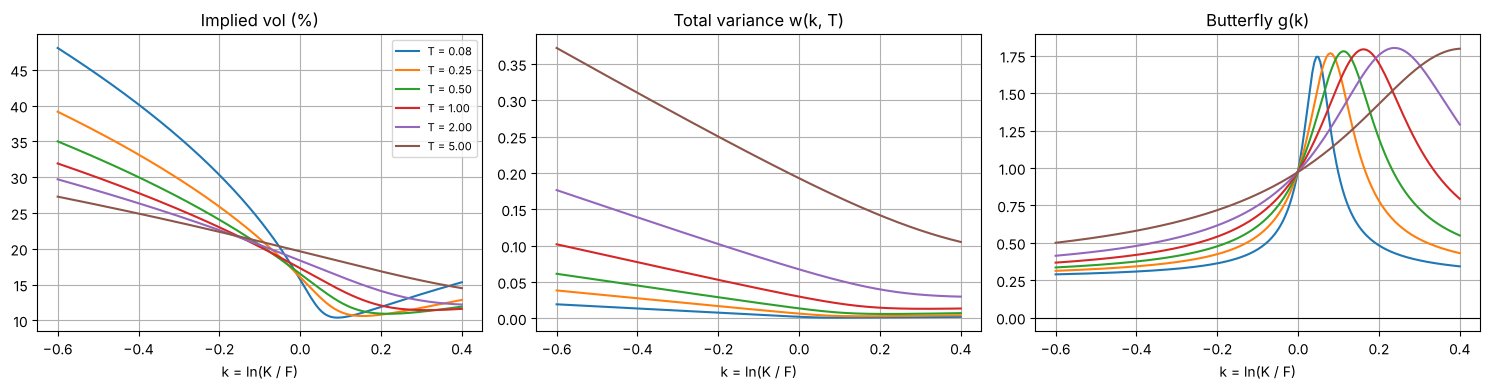

CASE min g(k) 0.289 (>= 0: no butterfly arbitrage); total variance increasing in T for every k: True


In [3]:
ks = np.linspace(-0.6, 0.4, 201)
mats = [1 / 12, 0.25, 0.5, 1.0, 2.0, 5.0]
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for T in mats:
    ax[0].plot(ks, surface.vol(ks, T) * 100, label=f"T = {T:.2f}")
    ax[1].plot(ks, surface.w(ks, T), label=f"T = {T:.2f}")
    ax[2].plot(ks, surface.butterfly_g(ks, T))
ax[0].set_title("Implied vol (%)"); ax[1].set_title("Total variance w(k, T)"); ax[2].set_title("Butterfly g(k)")
ax[2].axhline(0, color="k", lw=0.8)
ax[0].legend(fontsize=8)
for a in ax:
    a.set_xlabel("k = ln(K / F)")
plt.tight_layout(); plt.show()
g_min = min(surface.butterfly_g(ks, T).min() for T in mats)
Ts_fine = np.linspace(0.02, 6.0, 300)
calendar_ok = all(np.all(np.diff(surface.w(k, Ts_fine)) > 0) for k in ks)
print(f"CASE min g(k) {g_min:.3f} (>= 0: no butterfly arbitrage); total variance increasing in T for every k: {calendar_ok}")

## 3. Volatilidad local de Dupire

Dupire (1994) encuentra la única difusión $dS/S = \ldots + \sigma_{loc}(S,t)\,dW$ que reprecia todas las vanillas.
En varianza total (Gatheral 2006, ec. 1.10):
$$\sigma_{loc}^2(k,T) = \frac{\partial_T w}{1 - \frac{k}{w}\partial_k w + \frac14\left(-\frac14 - \frac1w + \frac{k^2}{w^2}\right)(\partial_k w)^2 + \frac12 \partial_{kk} w}$$
La implícita es, aproximadamente, una media de la local a lo largo del camino entre el spot y el strike; por eso
cerca del ATM la pendiente de la local es del orden del doble de la pendiente de la implícita (la *regla del dos*).

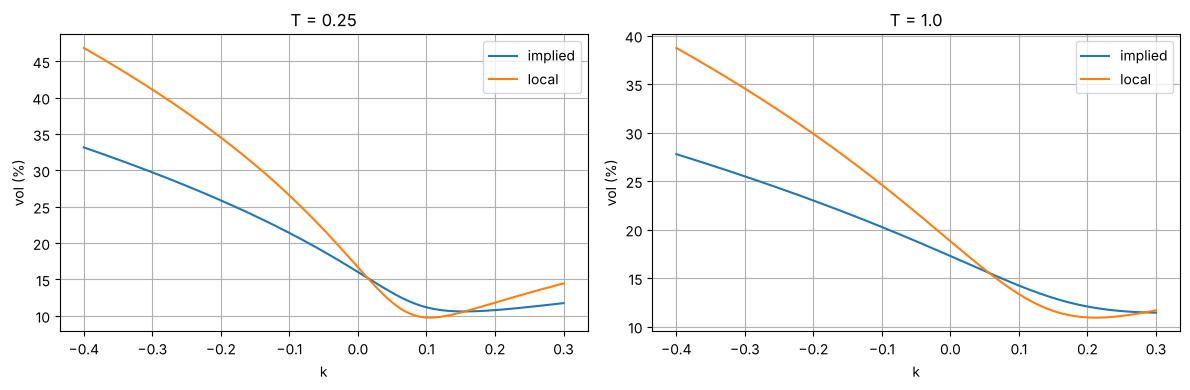

   T  implied skew dvol/dk  local skew dvol/dk  ratio
0.10                -0.875              -1.546  1.766
0.25                -0.580              -1.053  1.816
1.00                -0.309              -0.594  1.919
CASE rule of two: local / implied ATM skew = 1.77 to 1.92


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
kk = np.linspace(-0.4, 0.3, 141)
for a, T in zip(ax, [0.25, 1.0]):
    a.plot(kk, surface.vol(kk, T) * 100, label="implied")
    a.plot(kk, [np.sqrt(surface.local_var(k, T)) * 100 for k in kk], label="local")
    a.set_title(f"T = {T}"); a.set_xlabel("k"); a.set_ylabel("vol (%)"); a.legend()
plt.tight_layout(); plt.show()
rows = []
for T in [0.1, 0.25, 1.0]:
    h = 0.01
    s_imp = (surface.vol(h, T) - surface.vol(-h, T)) / (2 * h)
    s_loc = (np.sqrt(surface.local_var(h, T)) - np.sqrt(surface.local_var(-h, T))) / (2 * h)
    rows.append({"T": T, "implied skew dvol/dk": s_imp, "local skew dvol/dk": s_loc, "ratio": s_loc / s_imp})
rule2 = pd.DataFrame(rows)
print(rule2.round(3).to_string(index=False))
print(f"CASE rule of two: local / implied ATM skew = {rule2.ratio.min():.2f} to {rule2.ratio.max():.2f}")

### Comprobación: la volatilidad local reprecia las vanillas

Se simulan 100.000 caminos con la volatilidad local (Euler en logaritmos, 500 pasos por año) y se comparan los
precios con los de la superficie implícita.

In [5]:
T = 1.0
x_T, _ = local_vol_mc(surface, T, n_paths=100000, seed=3)
F1, df1 = mkt.forward(T), mkt.P(T)
rep = []
for k in [-0.3, -0.2, -0.1, 0.0, 0.1]:
    K = F1 * np.exp(k)
    call = k >= 0
    pay = np.maximum(F1 * np.exp(x_T) - K, 0) if call else np.maximum(K - F1 * np.exp(x_T), 0)
    mc = df1 * pay.mean()
    bs = bs_price(F1, K, T, surface.vol(k, T), df1, call)
    rep.append({"k": k, "strike": K, "type": "call" if call else "put", "surface": bs, "local vol MC": mc,
                "error": mc / bs - 1, "MC vol": implied_vol(mc, F1, K, T, df1, call), "surface vol": surface.vol(k, T)})
rep = pd.DataFrame(rep)
print(rep.to_string(index=False, formatters={"strike": "{:,.0f}".format, "surface": "{:.2f}".format,
      "local vol MC": "{:.2f}".format, "error": "{:+.2%}".format, "MC vol": "{:.2%}".format, "surface vol": "{:.2%}".format}))
print(f"CASE local vol MC reprices 1y vanillas within {rep.error.abs().max():.2%} (E[S_T / F_T] = {np.exp(x_T).mean():.4f})")

   k strike type surface local vol MC  error MC vol surface vol
-0.3  3,638  put   61.85        62.20 +0.55% 25.53%      25.49%
-0.2  4,021  put  106.02       106.35 +0.31% 23.03%      23.00%
-0.1  4,443  put  185.12       185.80 +0.37% 20.31%      20.26%
 0.0  4,911 call  331.61       332.10 +0.15% 17.30%      17.27%
 0.1  5,427 call  102.29       102.77 +0.47% 14.26%      14.22%
CASE local vol MC reprices 1y vanillas within 0.55% (E[S_T / F_T] = 0.9999)


## 4. Heston: volatilidad estocástica

$$\frac{dS}{S} = \ldots + \sqrt{v}\,dW_1, \qquad dv = \kappa(\bar v - v)\,dt + \xi\sqrt v\,dW_2, \qquad dW_1 dW_2 = \rho\,dt$$
Tiene función característica cerrada; los precios salen por inversión de Fourier (Gil-Pelaez). La correlación
negativa genera el skew; la vol de la vol $\xi$, la curvatura; $\kappa$ controla cómo se aplana el skew con el
plazo. Se calibra a 18 volatilidades (3, 12 y 24 meses, seis strikes).

In [6]:
cal_T = [0.25, 1.0, 2.0]
cal_k = [-0.3, -0.2, -0.1, 0.0, 0.1, 0.2]
target = [(T, k, surface.vol(k, T)) for T in cal_T for k in cal_k]

def heston_vol(params, T, k):
    v0, kappa, theta, xi, rho = params
    K = np.exp(k)                       # forward normalised to 1, undiscounted
    c = heston_call(1.0, K, T, 1.0, v0, kappa, theta, xi, rho)
    if k < 0:
        return implied_vol(c - (1.0 - K), 1.0, K, T, 1.0, call=False)
    return implied_vol(c, 1.0, K, T, 1.0, call=True)

def resid(p, data):
    return np.array([heston_vol(p, T, k) - v for T, k, v in data])

fit = least_squares(resid, [0.03, 2.0, 0.04, 0.6, -0.7], args=(target,),
                    bounds=([1e-3, 0.1, 1e-3, 0.05, -0.99], [0.2, 10.0, 0.2, 3.0, 0.5]))
v0, kappa, theta, xi, rho_h = fit.x
err = pd.DataFrame(fit.fun.reshape(len(cal_T), len(cal_k)) * 1e4, index=[f"{T}y" for T in cal_T], columns=[f"k={k}" for k in cal_k])
print(f"Heston: v0 {v0:.4f} (vol {np.sqrt(v0):.1%}), kappa {kappa:.2f}, theta {theta:.4f} (vol {np.sqrt(theta):.1%}), xi {xi:.2f}, rho {rho_h:.2f}")
print("Model - surface (bp of vol)")
print(err.round(0))
feller = 2 * kappa * theta - xi ** 2
print(f"CASE Heston fit RMSE {np.sqrt((fit.fun ** 2).mean()) * 1e4:.0f} bp, worst {np.abs(fit.fun).max() * 1e4:.0f} bp; "
      f"Feller 2 kappa theta - xi^2 = {feller:+.3f}")

Heston: v0 0.0273 (vol 16.5%), kappa 1.99, theta 0.0523 (vol 22.9%), xi 0.68, rho -0.83
Model - surface (bp of vol)
       k=-0.3  k=-0.2  k=-0.1  k=0.0  k=0.1  k=0.2
0.25y   -43.0    -2.0    28.0    8.0  -30.0   55.0
1.0y     36.0    29.0    20.0    5.0  -22.0  -44.0
2.0y    -42.0   -26.0    -9.0   10.0   26.0   23.0
CASE Heston fit RMSE 29 bp, worst 55 bp; Feller 2 kappa theta - xi^2 = -0.248


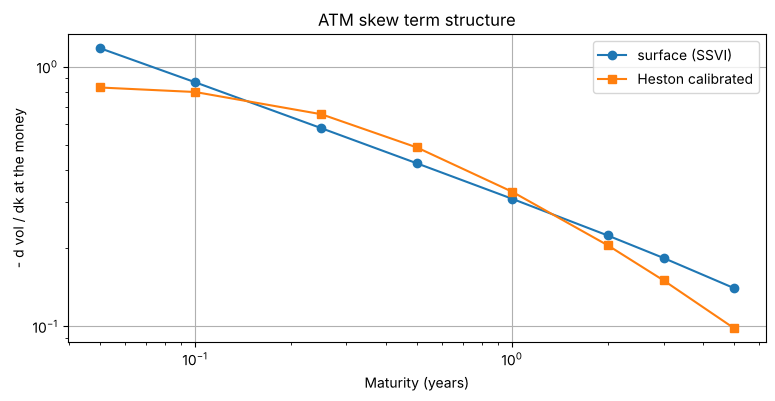

In [7]:
TT = np.array([0.05, 0.1, 0.25, 0.5, 1.0, 2.0, 3.0, 5.0])
h = 0.02
skew_ssvi = [(surface.vol(h, T) - surface.vol(-h, T)) / (2 * h) for T in TT]
skew_heston = [(heston_vol(fit.x, T, h) - heston_vol(fit.x, T, -h)) / (2 * h) for T in TT]
plt.loglog(TT, -np.array(skew_ssvi), "o-", label="surface (SSVI)")
plt.loglog(TT, -np.array(skew_heston), "s-", label="Heston calibrated")
plt.xlabel("Maturity (years)"); plt.ylabel("- d vol / dk at the money"); plt.legend()
plt.title("ATM skew term structure"); plt.show()

**Lectura.** Heston reproduce la forma general con cinco parámetros, pero no puede a la vez el skew de tres meses
y el de dos años: en el corto plazo el skew de Heston tiende a una constante, mientras que el de la superficie
sigue creciendo cerca de $T^{-1/2}$ (aquí $T^{-0{,}45}$, por el parámetro γ de SSVI). Por eso los desks usan volatilidad local o modelos
mixtos local-estocásticos (LSV) para exóticos: la local garantiza las vanillas y la parte estocástica da dinámica
realista al smile. La condición de Feller casi nunca se cumple en calibraciones de índices: la varianza puede
tocar cero, lo que exige cuidado en la simulación.

## 5. Caso: un hedge fund vende skew

**Situación.** Un hedge fund cree que los puts del índice están caros frente a las calls. Vende el risk reversal
a tres meses: vende el put 25Δ y compra la call 25Δ sobre 10.000 veces el índice (unos 50 M€ por pata), cobra la
diferencia de primas y cubre la delta con futuros. Le preocupa una caída fuerte. El banco que le da precio
pregunta: ¿cuánto pierde si el índice cae un 10 % de golpe?

La respuesta depende de cómo se mueve el smile:

- **Sticky strike**: la volatilidad de cada strike no cambia.
- **Sticky moneyness** (*sticky delta*): el smile se mueve con el spot; la volatilidad depende de K/F.
- **Volatilidad local**: la dinámica del propio modelo; se simula desde el nuevo spot con la misma función
  $\sigma_{loc}(S,t)$.

In [8]:
T = 0.25
F, df = mkt.forward(T), mkt.P(T)
Kp = round(F * np.exp(k_at_delta(T, 0.25, call=False)) / 25) * 25
Kc = round(F * np.exp(k_at_delta(T, 0.25, call=True)) / 25) * 25
N = 10000.0
g = mkt.growth(T)

def rr_value(Fx, vol_fn):
    return N * (bs_price(Fx, Kc, T, vol_fn(Kc), df, True) - bs_price(Fx, Kp, T, vol_fn(Kp), df, False))

def fwd_delta(Fx, K, v, call):
    d1 = (np.log(Fx / K) + 0.5 * v * v * T) / (v * np.sqrt(T))
    return df * g * (norm.cdf(d1) if call else norm.cdf(d1) - 1)

vol_today = lambda K: surface.vol(np.log(K / F), T)
v_start = rr_value(F, vol_today)
delta_units = N * (fwd_delta(F, Kc, vol_today(Kc), True) - fwd_delta(F, Kp, vol_today(Kp), False))
gk = {K: bs_greeks(mkt, K, T, vol_today(K), call=(K == Kc)) for K in [Kp, Kc]}
vega_rr = N * (gk[Kc]["vega"] - gk[Kp]["vega"])
vanna_rr = N * (gk[Kc]["vanna"] - gk[Kp]["vanna"])
print(f"Sell the {Kp:,.0f} put ({vol_today(Kp):.2%}), buy the {Kc:,.0f} call ({vol_today(Kc):.2%})")
print(f"CASE premium received {-v_start:,.0f} EUR; delta {delta_units:,.0f} index units -> sell {delta_units / 10:,.0f} futures; "
      f"vega {vega_rr:,.0f} EUR/pt; vanna {vanna_rr:,.0f} units per vol point")

Sell the 4,725 put (19.40%), buy the 5,250 call (13.45%)
CASE premium received 241,706 EUR; delta 5,137 index units -> sell 514 futures; vega 2,125 EUR/pt; vanna 265 units per vol point


In [9]:
shock = 0.90
F_new = shock * F                                   # no dividend before May: the 3m forward moves with spot
hedge_pnl = -delta_units * (shock - 1) * mkt.spot
sticky_strike = rr_value(F_new, vol_today)
sticky_moneyness = rr_value(F_new, lambda K: surface.vol(np.log(K / F_new), T))
# local vol: same random numbers from today's spot and from the shocked spot; the first run removes the MC bias
x_base, _ = local_vol_mc(surface, T, n_paths=150000, steps_per_year=2000, seed=7)
x_shock, _ = local_vol_mc(surface, T, n_paths=150000, steps_per_year=2000, seed=7, x0=np.log(shock))

def rr_mc(x):
    ST = F * np.exp(x)
    return N * df * (np.maximum(ST - Kc, 0).mean() - np.maximum(Kp - ST, 0).mean())

local_vol = rr_mc(x_shock) - (rr_mc(x_base) - v_start)
scen = pd.DataFrame({"options": {"sticky strike": sticky_strike - v_start, "sticky moneyness": sticky_moneyness - v_start,
                                 "local vol": local_vol - v_start}})
scen["futures hedge"] = hedge_pnl
scen["total"] = scen.sum(axis=1)
print("P&L of the hedge fund after an instant 10% fall (EUR)")
print(scen.map(lambda v: f"{v:,.0f}"))
print(f"CASE total P&L: sticky strike {scen.total['sticky strike']:,.0f}, sticky moneyness {scen.total['sticky moneyness']:,.0f}, "
      f"local vol {scen.total['local vol']:,.0f} EUR")

P&L of the hedge fund after an instant 10% fall (EUR)
                     options futures hedge     total
sticky strike     -2,739,315     2,568,325  -170,991
sticky moneyness  -2,284,861     2,568,325   283,464
local vol         -3,382,996     2,568,325  -814,672
CASE total P&L: sticky strike -170,991, sticky moneyness 283,464, local vol -814,672 EUR


In [10]:
def mc_vol(x, Fx, K):
    ST = F * np.exp(x)
    call = K >= Fx
    p = df * (np.maximum(ST - K, 0) if call else np.maximum(K - ST, 0)).mean()
    return implied_vol(p, Fx, K, T, df, call)

after = []
for label, K in [("25d put strike", Kp), ("new ATM (0.9 F)", F_new), ("25d call strike", Kc)]:
    bias = mc_vol(x_base, F, K) - vol_today(K)
    after.append({"strike": label, "today": vol_today(K), "sticky strike": vol_today(K),
                  "sticky moneyness": surface.vol(np.log(K / F_new), T), "local vol": mc_vol(x_shock, F_new, K) - bias})
after = pd.DataFrame(after).set_index("strike")
print("3m implied vols after the fall")
print(after.map(lambda v: f"{v:.2%}"))
atm_move = {c: after.loc["new ATM (0.9 F)", c] - surface.vol(0.0, T) for c in ["sticky strike", "sticky moneyness", "local vol"]}
skew_move = surface.vol(np.log(shock), T) - surface.vol(0.0, T)
print("ATM vol change: " + ", ".join(f"{c} {v * 100:+.1f} pts" for c, v in atm_move.items()))
print(f"CASE skew stickiness ratio (ATM move / move along today's smile): local vol {atm_move['local vol'] / skew_move:.2f}, "
      f"sticky strike 1, sticky moneyness 0")

3m implied vols after the fall
                  today sticky strike sticky moneyness local vol
strike                                                          
25d put strike   19.40%        19.40%           13.45%    28.46%
new ATM (0.9 F)  21.66%        21.66%           16.03%    31.24%
25d call strike  13.45%        13.45%           10.61%    20.44%
ATM vol change: sticky strike +5.6 pts, sticky moneyness +0.0 pts, local vol +15.2 pts
CASE skew stickiness ratio (ATM move / move along today's smile): local vol 2.70, sticky strike 1, sticky moneyness 0


**Lectura.**

- Con *sticky moneyness* el hedge fund incluso gana: el put vendido pasa a estar cerca del dinero, pero su
  volatilidad baja porque el smile se ha desplazado con el spot.
- Con *sticky strike* pierde algo: la gamma corta del put le cuesta más de lo que gana la cobertura.
- Con volatilidad local pierde mucho más: el modelo hace subir la volatilidad de cada strike al caer el spot
  (la volatilidad local es alta a la izquierda), y el put vendido se encarece.
- La volatilidad ATM sube mucho más de lo que indica moverse por el smile de hoy. El cociente entre ambas cosas
  (*skew stickiness ratio*, Bergomi) es 0 en sticky moneyness, 1 en sticky strike y cerca de 2 en volatilidad
  local para movimientos pequeños (la regla del dos aplicada a la dinámica); con una caída del 10 % y un skew
  corto tan pronunciado sale 2,7. En índices se observa algo entre 1 y 2.
- La delta de Black-Scholes no ve esta dinámica. Quien vende el risk reversal es largo vanna (su delta sube si
  sube la volatilidad) y, como en renta variable la volatilidad sube cuando cae el índice, se encuentra más largo
  justo cuando el mercado cae: la cobertura de Black-Scholes se queda corta. El ejercicio avanzado calcula la
  delta de volatilidad local.

## 6. Comprobaciones

In [11]:
assert g_min > 0 and calendar_ok
assert (qt["RR 25d"] < 0).all()
assert 1.5 < rule2.ratio.min() and rule2.ratio.max() < 2.2
assert rep.error.abs().max() < 0.01
assert np.sqrt((fit.fun ** 2).mean()) < 0.005
assert scen.total["sticky moneyness"] > scen.total["sticky strike"] > scen.total["local vol"]
assert after.loc["25d put strike", "local vol"] > after.loc["25d put strike", "sticky strike"] > after.loc["25d put strike", "sticky moneyness"]
assert 1.5 < atm_move["local vol"] / skew_move < 3.0
print("All checks passed")

All checks passed


## Ejercicios

1. **Básico.** Con la tabla de cotizaciones, ¿cuánto cuesta en puntos de volatilidad el put 25Δ a un año frente a la
   call 25Δ? Convierte el skew 90-110 a un año en puntos de volatilidad por cada 1 % de moneyness.
2. **Intermedio.** Calibra Heston solo al smile de tres meses. ¿Cómo ajusta después el smile a dos años?
3. **Avanzado.** Calcula la delta del risk reversal en volatilidad local, moviendo el spot ±1 % en la simulación con
   los mismos números aleatorios, y repite la pérdida del escenario con esa delta como cobertura.

## Soluciones

In [12]:
q1 = qt[qt["T"] == 1.0].iloc[0]
print(f"1y: the 25d put trades {-q1['RR 25d'] * 100:.1f} vol points above the 25d call; "
      f"90-110 skew {q1['skew 90-110'] * 100:.1f} pts = {q1['skew 90-110'] * 100 / 20:.2f} pts per 1% of moneyness")

1y: the 25d put trades 6.7 vol points above the 25d call; 90-110 skew 6.0 pts = 0.30 pts per 1% of moneyness


In [13]:
target_3m = [(0.25, k, surface.vol(k, 0.25)) for k in cal_k]
fit_3m = least_squares(resid, fit.x, args=(target_3m,), bounds=([1e-3, 0.1, 1e-3, 0.05, -0.99], [0.2, 10.0, 0.2, 3.0, 0.5]))
err_2y = np.array([heston_vol(fit_3m.x, 2.0, k) - surface.vol(k, 2.0) for k in cal_k])
print(f"3m-only fit: 3m RMSE {np.sqrt((fit_3m.fun ** 2).mean()) * 1e4:.0f} bp; 2y errors (bp): {np.round(err_2y * 1e4).astype(int)}")
print("A Heston parameter set fitted to one maturity misprices the others: the term structure of the skew is the hard part.")

3m-only fit: 3m RMSE 7 bp; 2y errors (bp): [-359 -268 -169  -60   51  137]
A Heston parameter set fitted to one maturity misprices the others: the term structure of the skew is the hard part.


In [14]:
x_up, _ = local_vol_mc(surface, T, n_paths=150000, steps_per_year=2000, seed=7, x0=np.log(1.01))
x_dn, _ = local_vol_mc(surface, T, n_paths=150000, steps_per_year=2000, seed=7, x0=np.log(0.99))
delta_lv = (rr_mc(x_up) - rr_mc(x_dn)) / (0.02 * mkt.spot)
hedge_lv = -delta_lv * (shock - 1) * mkt.spot
print(f"Black-Scholes delta {delta_units:,.0f} units; local-vol delta {delta_lv:,.0f} units")
print(f"Local-vol scenario with the local-vol hedge: {(local_vol - v_start) + hedge_lv:,.0f} EUR "
      f"(vs {scen.total['local vol']:,.0f} with the BS hedge)")
print("If the market really moves like local vol, the position is longer delta than Black-Scholes says: the right")
print("hedge sells more futures, and the loss in a crash shrinks.")

Black-Scholes delta 5,137 units; local-vol delta 5,753 units
Local-vol scenario with the local-vol hedge: -506,526 EUR (vs -814,672 with the BS hedge)
If the market really moves like local vol, the position is longer delta than Black-Scholes says: the right
hedge sells more futures, and the loss in a crash shrinks.
